# LeetCode #164: Maximum Gap

https://leetcode.com/problems/maximum-gap/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Sort then scan | O(n log n) | O(1) |
| Radix Sort / Bucket Sort ★ | O(n) | O(n) |

## Understanding the Methods
### Sort then scan
Sort the array and find the maximum difference between consecutive elements. Simple O(n log n).

### Optimal: Bucket Sort ★
By pigeonhole principle, if we distribute n numbers into n-1 buckets, the maximum gap must span at least one empty bucket. Set bucket size = ceil((max-min)/(n-1)). Each bucket tracks its min/max. The max gap is between min of one bucket and max of the previous non-empty bucket. This achieves O(n) time.

## Solutions
### C#

In [ ]:
public class Solution {
    public int MaximumGap(int[] nums) {
        if (nums.Length < 2) return 0;
        int n = nums.Length;
        int minVal = nums.Min(), maxVal = nums.Max();
        if (minVal == maxVal) return 0;
        int bucketSize = Math.Max(1, (maxVal - minVal) / (n - 1));
        int bucketCount = (maxVal - minVal) / bucketSize + 1;
        var bMin = new int[bucketCount];
        var bMax = new int[bucketCount];
        var used = new bool[bucketCount];
        Array.Fill(bMin, int.MaxValue);
        Array.Fill(bMax, int.MinValue);
        foreach (int num in nums) {
            int idx = (num - minVal) / bucketSize;
            bMin[idx] = Math.Min(bMin[idx], num);
            bMax[idx] = Math.Max(bMax[idx], num);
            used[idx] = true;
        }
        int gap = 0, prevMax = minVal;
        for (int i = 0; i < bucketCount; i++) {
            if (!used[i]) continue;
            gap = Math.Max(gap, bMin[i] - prevMax);
            prevMax = bMax[i];
        }
        return gap;
    }
}

### Python

In [ ]:
from typing import List
import math

class Solution:
    def maximumGap(self, nums: List[int]) -> int:
        n = len(nums)
        if n < 2:
            return 0
        min_v, max_v = min(nums), max(nums)
        if min_v == max_v:
            return 0
        bucket_size = max(1, (max_v - min_v) // (n - 1))
        bucket_count = (max_v - min_v) // bucket_size + 1
        buckets = [[float('inf'), float('-inf')] for _ in range(bucket_count)]
        for num in nums:
            idx = (num - min_v) // bucket_size
            buckets[idx][0] = min(buckets[idx][0], num)
            buckets[idx][1] = max(buckets[idx][1], num)
        gap, prev_max = 0, min_v
        for lo, hi in buckets:
            if lo == float('inf'):
                continue
            gap = max(gap, lo - prev_max)
            prev_max = hi
        return gap

### Go

In [ ]:
package main

import (
    "fmt"
    "math"
)

func maximumGap(nums []int) int {
    n := len(nums)
    if n < 2 {
        return 0
    }
    minV, maxV := nums[0], nums[0]
    for _, v := range nums {
        if v < minV { minV = v }
        if v > maxV { maxV = v }
    }
    if minV == maxV { return 0 }
    bucketSize := (maxV - minV + n - 2) / (n - 1)
    if bucketSize == 0 { bucketSize = 1 }
    bucketCount := (maxV-minV)/bucketSize + 1
    bMin := make([]int, bucketCount)
    bMax := make([]int, bucketCount)
    used := make([]bool, bucketCount)
    for i := range bMin { bMin[i] = math.MaxInt32; bMax[i] = math.MinInt32 }
    for _, num := range nums {
        idx := (num - minV) / bucketSize
        if num < bMin[idx] { bMin[idx] = num }
        if num > bMax[idx] { bMax[idx] = num }
        used[idx] = true
    }
    gap, prevMax := 0, minV
    for i := 0; i < bucketCount; i++ {
        if !used[i] { continue }
        if bMin[i]-prevMax > gap { gap = bMin[i] - prevMax }
        prevMax = bMax[i]
    }
    return gap
}

func main() {
    fmt.Println(maximumGap([]int{3, 6, 9, 1})) // 3
}

### Rust

In [ ]:
pub struct Solution;

impl Solution {
    pub fn maximum_gap(nums: Vec<i32>) -> i32 {
        let n = nums.len();
        if n < 2 { return 0; }
        let min_v = *nums.iter().min().unwrap();
        let max_v = *nums.iter().max().unwrap();
        if min_v == max_v { return 0; }
        let bucket_size = ((max_v - min_v) as usize).max(1) / (n - 1).max(1) + 1;
        let bucket_count = ((max_v - min_v) as usize) / bucket_size + 1;
        let mut b_min = vec![i32::MAX; bucket_count];
        let mut b_max = vec![i32::MIN; bucket_count];
        for &num in &nums {
            let idx = ((num - min_v) as usize) / bucket_size;
            b_min[idx] = b_min[idx].min(num);
            b_max[idx] = b_max[idx].max(num);
        }
        let (mut gap, mut prev_max) = (0i32, min_v);
        for i in 0..bucket_count {
            if b_min[i] == i32::MAX { continue; }
            gap = gap.max(b_min[i] - prev_max);
            prev_max = b_max[i];
        }
        gap
    }
}

## Example Scenarios

### 1. Common Case — Small Spread
**Input:** `nums = [3,6,9,1]`

Sorted order is `[1,3,6,9]`. Bucket size is `(9-1)//3 = 2`. Scanning buckets left to right, the largest adjacent gap is `6-3 = 3`.

### 2. Slightly Complex — Pigeonhole Empty Bucket
**Input:** `nums = [10,3,8,100,20]`

With 5 values and bucket size `24`, three middle buckets stay empty. The max gap must straddle them: `100 - 20 = 80`, found without a full sort.

### 3. Edge Case: Time — Uniform Spacing
**Input:** `nums = [1,2,3,4,5]`

Each value lands in its own size-1 bucket. Bucketing and the single scan are both $O(n)$, beating the $O(n \log n)$ sort. Max gap is `1`.

### 4. Edge Case: Space — Two Elements, Huge Range
**Input:** `nums = [1,10000000]`

Only two numbers, so there are two buckets regardless of the enormous span. The gap is the full distance `10000000 - 1 = 9999999`.

### 5. Almost-Impossible but Plausible — All Identical
**Input:** `nums = [5,5,5,5]`

Here `min == max`, so the method short-circuits: there are no gaps at all and the answer is `0`.


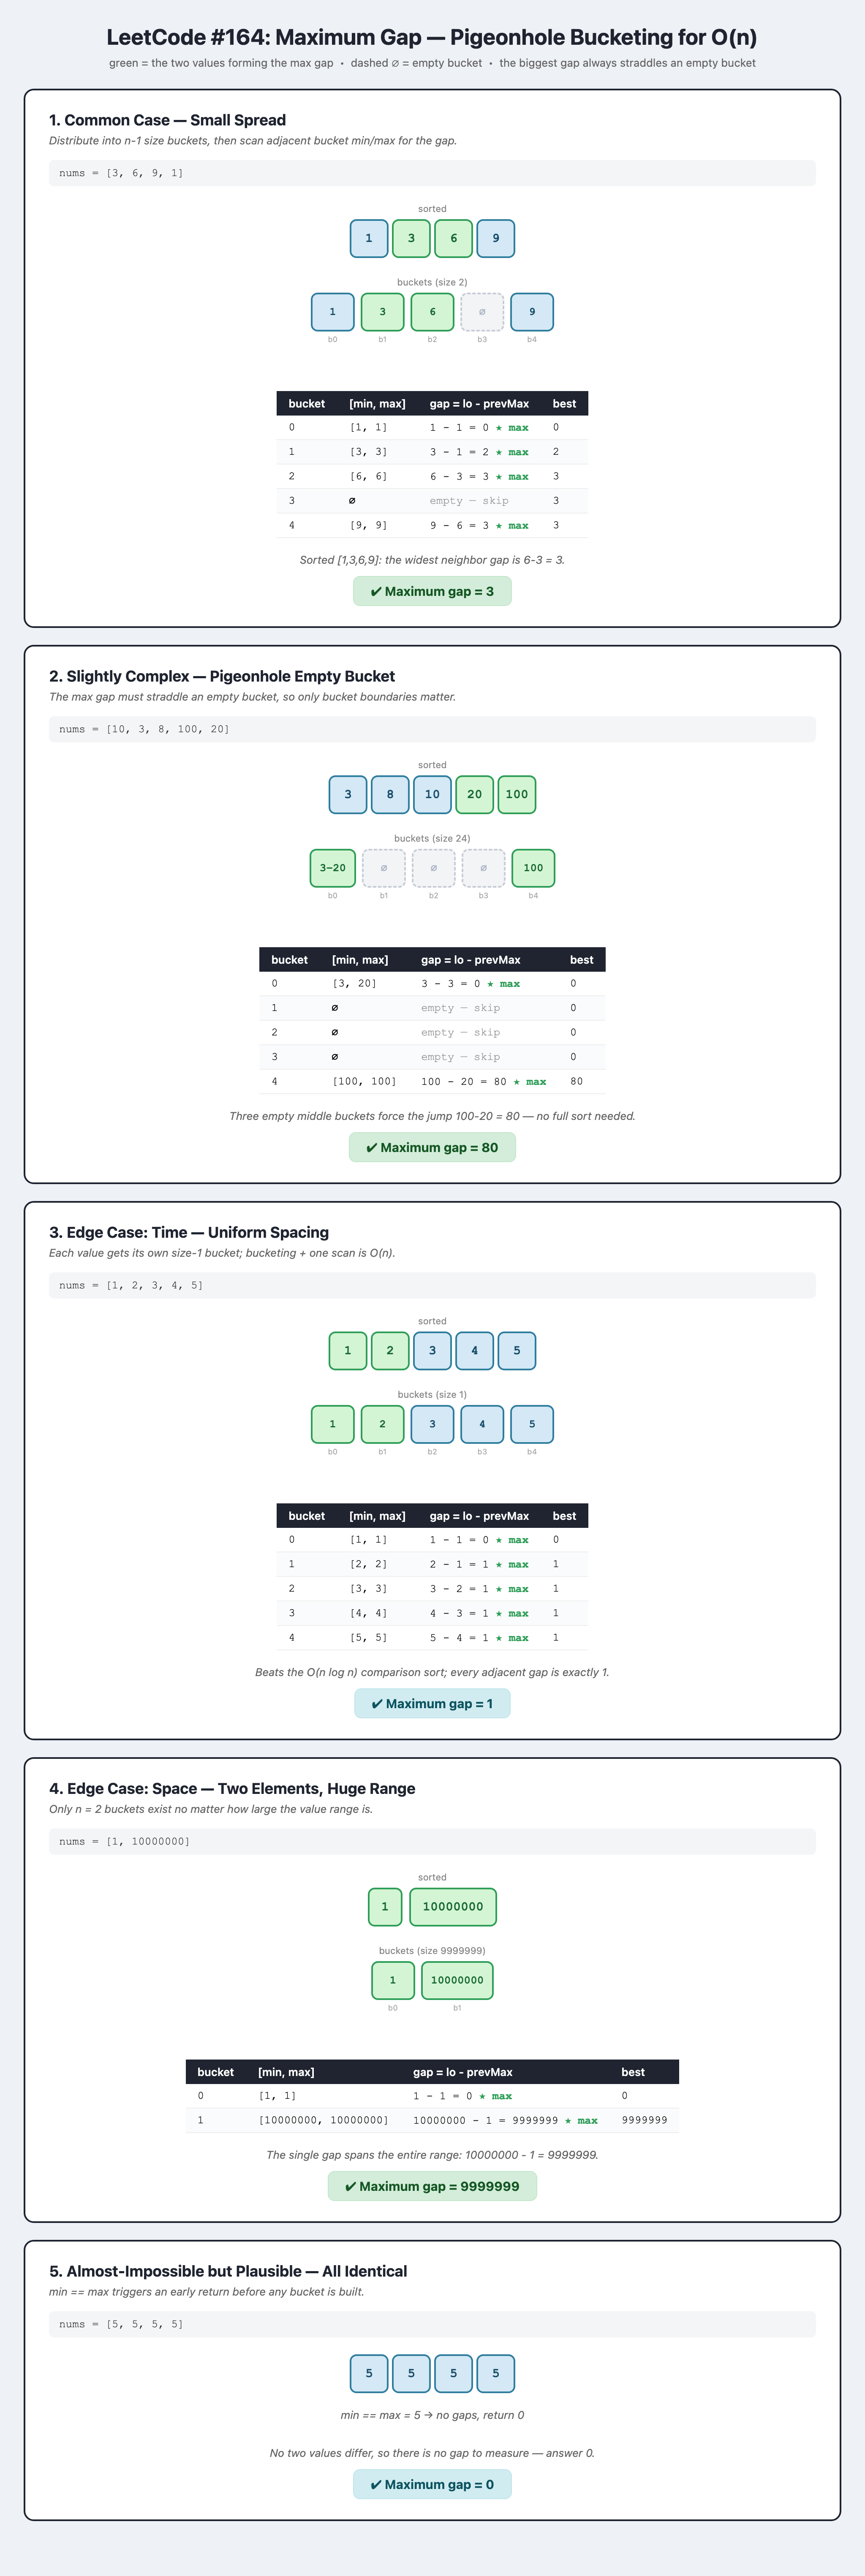